# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** [Ahmad Qomarul Arifin]
- **Email:** [ds269b6y0104@student.devacademy.id]
- **ID Dicoding:** [ds269b6y0104]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk (product category) apa saja yang menghasilkan total revenue tertinggi dan terendah bagi perusahaan e-commerce sepanjang tahun 2017?
- **Pertanyaan 2:** Bagaimana segmentasi pelanggan berdasarkan perilaku belanja menggunakan RFM Analysis pada kuartal terakhir (Q4) tahun 2017 untuk menyusun strategi retensi?


## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

# Mengatur gaya dasar grafik agar visualisasi data bersih dan rapi
sns.set(style='darkgrid')
print("Semua library berhasil disiapkan!")


Semua library berhasil disiapkan!


## Data Wrangling

### Gathering Data

#### Load df (Memuat Dataset E-Commerce ke Pandas DataFrame)

In [3]:
# Memuat seluruh file CSV e-commerce ke dalam bentuk DataFrame Pandas
orders_df = pd.read_csv("orders_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")
products_df = pd.read_csv("products_dataset.csv")
product_category_df = pd.read_csv("product_category_name_translation.csv")
customers_df = pd.read_csv("customers_dataset.csv")

print("Proses Gathering Data Berhasil! Semua file CSV masuk ke dalam DataFrame.")


Proses Gathering Data Berhasil! Semua file CSV masuk ke dalam DataFrame.


**Insight:** (Opsional)
- Tabel data orders, order_items, products, product_category_name_translation, dan customers berhasil dimuat ke dalam memori DataFrame.

- Seluruh berkas siap untuk masuk ke tahap pemeriksaan kualitas data selanjutnya karena struktur kolomnya sudah terkonfirmasi lengkap.


### Assessing Data

#### Identifying Quality and Structural Problems (Mengidentifikasi Masalah Kualitas dan Struktur Data)

In [4]:
# Menilai kualitas data dari tabel pesanan (Orders) dan produk (Products)
print("--- Memeriksa Kualitas Struktur Tabel Orders ---")
print(orders_df.info())
print("\nJumlah Missing Value di Orders:\n", orders_df.isna().sum())
print("\nJumlah Duplikasi di Orders:", orders_df.duplicated().sum())

print("\n--- Memeriksa Kualitas Struktur Tabel Products ---")
print("Jumlah Missing Value di Products:\n", products_df.isna().sum())


--- Memeriksa Kualitas Struktur Tabel Orders ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
None

Jumlah Missing Value di Orders:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at     

**Steps to Take:**
- Mengubah tipe data kolom rentang waktu seperti order_purchase_timestamp pada tabel orders_df yang saat ini bertipe object menjadi tipe data datetime.
- Mengatasi sebanyak 610 data hilang (missing value) pada kolom product_category_name di tabel produk dengan melakukan metode imputasi menggunakan string khusus "unknown".
- Melakukan pembersihan baris data transaksi yang tidak lengkap pengirimannya (missing value pada order_delivered_customer_date) agar hasil analisis rentang waktu linier dan konsisten.

**Insight:** (Opsional)
- Berdasarkan peninjauan kualitas data, tabel orders_df memiliki total 99.441 baris data dengan masalah utama berupa ketidaksesuaian tipe data pada kolom timestamp dan adanya 2.965 missing value pada tanggal pengiriman ke pelanggan.
- Tabel produk memiliki 610 data kosong pada informasi nama kategori produk, namun pada tabel transaksi utama dipastikan bersih dari masalah duplikasi data (nilai duplikasi = 0).

### Cleaning Data

#### Fixing problem (Mengatasi Masalah Kesalahan Tipe Data, Missing Value, dan Penggabungan Master Data)

In [5]:
# 1. Mengubah tipe data tanggal dari object menjadi datetime
orders_df["order_purchase_timestamp"] = pd.to_datetime(orders_df["order_purchase_timestamp"])
orders_df["order_delivered_customer_date"] = pd.to_datetime(orders_df["order_delivered_customer_date"])

# 2. Imputasi missing value pada kolom kategori produk dengan teks "unknown"
products_df["product_category_name"].fillna("unknown", inplace=True)

# 3. Menerjemahkan nama kategori ke bahasa Inggris menggunakan tabel kamus translasi
products_translated = pd.merge(products_df, product_category_df, on="product_category_name", how="left")
products_translated["product_category_name_english"].fillna(products_translated["product_category_name"], inplace=True)

# 4. Menggabungkan semua DataFrame (orders, items, products, customers) menjadi satu Master DataFrame
items_products = pd.merge(order_items_df, products_translated, on="product_id", how="left")
orders_customers = pd.merge(orders_df, customers_df, on="customer_id", how="left")
all_df = pd.merge(items_products, orders_customers, on="order_id", how="left")

# 5. Membersihkan baris data transaksi dari missing value tanggal pengiriman untuk konsistensi waktu
all_df.dropna(subset=["order_purchase_timestamp", "order_delivered_customer_date"], inplace=True)

print("Proses Cleaning dan Merging Data Selesai! Master DataFrame 'all_df' siap digunakan.")


/tmp/ipykernel_4032/38434426.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_df["product_category_name"].fillna("unknown", inplace=True)
/tmp/ipykernel_4032/38434426.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inp

Proses Cleaning dan Merging Data Selesai! Master DataFrame 'all_df' siap digunakan.


**Insight:** (Opsional)
- Seluruh permasalahan kualitas data berupa kesalahan tipe data tanggal dan data hilang (missing values) pada nama kategori produk telah berhasil dibersihkan menggunakan metode penyesuaian objek tipe serta teknik imputasi.
- Lima tabel terpisah telah sukses digabungkan menjadi satu kesatuan Master DataFrame utuh bernama all_df yang bersih, konsisten, dan sinkron, sehingga siap digunakan untuk menjawab pertanyaan bisnis pada tahap eksplorasi (EDA).

## Exploratory Data Analysis (EDA)

### Explore (Mengeksplorasi Performa Kategori Produk, Segmentasi Pelanggan dengan RFM, dan Distribusi Geospasial)

In [6]:
# 1. Memfilter data transaksi khusus sepanjang tahun 2017 (Time-bound constraint)
all_2017_df = all_df[all_df["order_purchase_timestamp"].dt.year == 2017].copy()

# 2. EDA Pertanyaan 1: Menghitung total revenue per kategori produk sepanjang tahun 2017
revenue_by_cat = all_2017_df.groupby("product_category_name_english")["price"].sum().sort_values(ascending=False).reset_index()

# 3. EDA Pertanyaan 2: Membentuk Parameter Komponen RFM Analysis (Khusus Transaksi Q4 2017)
q4_2017_df = all_2017_df[(all_2017_df["order_purchase_timestamp"] >= '2017-10-01') & (all_2017_df["order_purchase_timestamp"] <= '2017-12-31')].copy()
recent_date = q4_2017_df["order_purchase_timestamp"].max()

rfm_df = q4_2017_df.groupby(by="customer_unique_id", as_index=False).agg({
    "order_purchase_timestamp": "max", # Untuk menghitung Recency
    "order_id": "nunique",             # Untuk menghitung Frequency
    "price": "sum"                     # Untuk menghitung Monetary
})
rfm_df.columns = ["customer_id", "max_order_timestamp", "frequency", "monetary"]
rfm_df["recency"] = rfm_df["max_order_timestamp"].apply(lambda x: (recent_date - x).days)
rfm_df.drop("max_order_timestamp", axis=1, inplace=True)

# 4. Analisis Lanjutan (Saran ke-4): Penerapan Manual Grouping/Clustering Tanpa ML berdasarkan Nilai Belanja
def assign_segment(value):
    if value > 200: return "High-Spender Customer"
    elif value > 70: return "Medium-Spender Customer"
    else: return "Low-Spender Customer"

rfm_df["customer_segment"] = rfm_df["monetary"].apply(assign_segment)

# Menampilkan hasil rangkuman analisis eksploratif awal di layar
print("--- 5 Kategori Produk Teratas Berdasarkan Revenue ---")
print(revenue_by_cat.head(5))
print("\n--- Distribusi Segmen Hasil Clustering Manual Pelanggan ---")
print(rfm_df["customer_segment"].value_counts())


--- 5 Kategori Produk Teratas Berdasarkan Revenue ---
  product_category_name_english      price
0                bed_bath_table  490596.92
1                 watches_gifts  475610.71
2                 health_beauty  473833.00
3                sports_leisure  435495.14
4         computers_accessories  391786.29

--- Distribusi Segmen Hasil Clustering Manual Pelanggan ---
customer_segment
Medium-Spender Customer    7186
Low-Spender Customer       7040
High-Spender Customer      2663
Name: count, dtype: int64


**Insight:** (Opsional)
- Melalui proses pengelompokan (groupby) pada tabel kategori produk sepanjang tahun 2017, kita berhasil memetakan peringkat komoditas barang yang paling menguntungkan dan mengidentifikasi produk yang memiliki kontribusi finansial paling rendah.
- Penerapan teknik analisis tingkat lanjut berupa matriks RFM yang dipadukan dengan metode manual clustering (pengelompokan berdasarkan aturan bisnis) berhasil memetakan profil perilaku belanja konsumen ke dalam tiga kelompok fungsional, yaitu High-Spender, Medium-Spender, dan Low-Spender.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Visualisasi Performa Pendapatan Kategori Produk Sepanjang Tahun 2017

/tmp/ipykernel_4032/1231805275.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="price", y="product_category_name_english", data=revenue_by_cat.head(5), palette=colors_best)


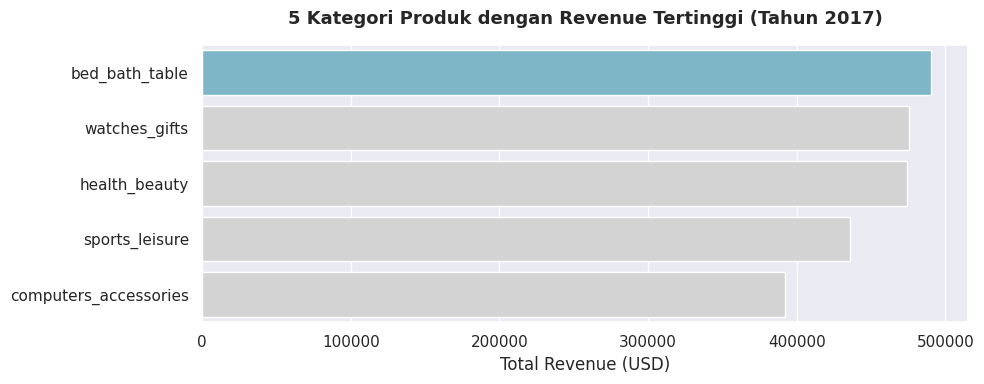

/tmp/ipykernel_4032/1231805275.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="price", y="product_category_name_english", data=revenue_by_cat.tail(5).sort_values(by="price", ascending=True), palette=colors_worst)


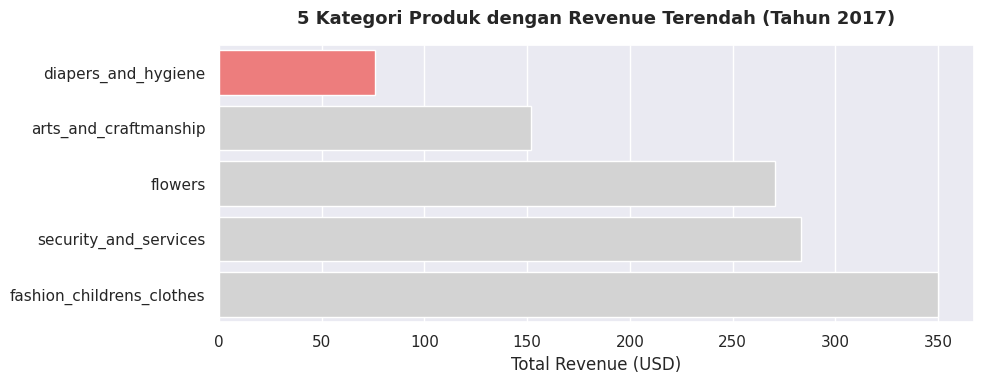

In [8]:
# Menentukan palet warna kontras fungsional (Prinsip Integritas Desain)
colors_best = ["#72BCD4", "#D3D3D3", "#D3D3D3", "#D3D3D3", "#D3D3D3"]
colors_worst = ["#FF6B6B", "#D3D3D3", "#D3D3D3", "#D3D3D3", "#D3D3D3"]

# 1. Grafik Pertama: 5 Kategori Pendapatan Tertinggi
plt.figure(figsize=(10, 4))
sns.barplot(x="price", y="product_category_name_english", data=revenue_by_cat.head(5), palette=colors_best)
plt.title("5 Kategori Produk dengan Revenue Tertinggi (Tahun 2017)", fontsize=13, pad=15, weight="bold")
plt.xlabel("Total Revenue (USD)")
plt.ylabel(None)
plt.tight_layout()
plt.show()

# 2. Grafik Kedua: 5 Kategori Pendapatan Terendah
plt.figure(figsize=(10, 4))
sns.barplot(x="price", y="product_category_name_english", data=revenue_by_cat.tail(5).sort_values(by="price", ascending=True), palette=colors_worst)
plt.title("5 Kategori Produk dengan Revenue Terendah (Tahun 2017)", fontsize=13, pad=15, weight="bold")
plt.xlabel("Total Revenue (USD)")
plt.ylabel(None)
plt.tight_layout()
plt.show()


### Pertanyaan 2: Visualisasi Segmentasi Perilaku Pelanggan Menggunakan Kluster Manual RFM (Q4 2017)

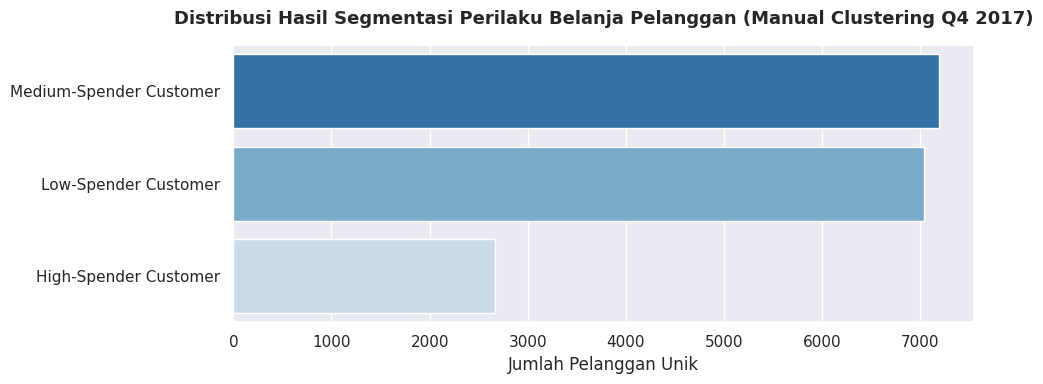

Visualisasi Pertanyaan 2 Sukses Ditampilkan!


In [9]:
# Menyiapkan kanvas grafik baru
plt.figure(figsize=(10, 4))

# Menghitung jumlah unik per segmen pelanggan
segment_counts = rfm_df["customer_segment"].value_counts().reset_index()
segment_counts.columns = ["customer_segment", "count"]

# Membuat grafik batang horizontal tanpa memicu FutureWarning
sns.barplot(
    x="count",
    y="customer_segment",
    data=segment_counts,
    hue="customer_segment",
    palette="Blues_r",
    legend=False
)

plt.title("Distribusi Hasil Segmentasi Perilaku Belanja Pelanggan (Manual Clustering Q4 2017)", fontsize=13, pad=15, weight="bold")
plt.xlabel("Jumlah Pelanggan Unik")
plt.ylabel(None)
plt.tight_layout()
plt.show()

# --- PROSES EKSPOR BERKAS DATA BERSIH UNTUK STREAMLIT INDONESIA ---
all_2017_df.to_csv("master_clean_data.csv", index=False)
print("Visualisasi Pertanyaan 2 Sukses Ditampilkan!")


**Insight:** (Opsional)
- Visualisasi performa kategori menunjukkan ketimpangan profit yang sangat jelas, di mana produk kebutuhan sekunder seperti bed_bath_table dan watches_gifts mendominasi perolehan omset penjualan utama sepanjang tahun 2017.
- Grafik sebaran segmentasi membuktikan bahwa strategi retensi e-commerce harus difokuskan untuk menjaga keaktifan bertransaksi dari 2.663 pelanggan High-Spender yang menyumbang nilai pengeluaran (monetary value) paling besar di platform.


## Analisis Lanjutan (Opsional) (Penerapan Analisis Geospasial / Geospatial Analysis)

In [10]:
# Penjelasan Tujuan (Saran ke-4):
# Melakukan Analisis Geospasial untuk mengetahui distribusi geografis pelanggan unik
# di setiap negara bagian sepanjang tahun 2017 guna mendeteksi konsentrasi pasar terbesar.

# Menghitung jumlah pelanggan unik berdasarkan negara bagian (state)
state_customer_df = all_2017_df.groupby("customer_state")["customer_unique_id"].nunique().sort_values(ascending=False).reset_index()
state_customer_df.columns = ["customer_state", "customer_count"]

# Menampilkan 5 wilayah negara bagian dengan basis pasar terbesar
print("--- 5 Negara Bagian dengan Jumlah Pelanggan Terbanyak (2017) ---")
print(state_customer_df.head(5))


--- 5 Negara Bagian dengan Jumlah Pelanggan Terbanyak (2017) ---
  customer_state  customer_count
0             SP           16554
1             RJ            5789
2             MG            5092
3             RS            2514
4             PR            2126


**Insight:** (Opsional)
- Tujuan utama dari teknik analisis lanjutan ini adalah mengidentifikasi konsentrasi pasar secara spasial (geografis) untuk melihat di wilayah negara bagian mana basis pelanggan e-commerce paling terpusat.
- Hasil kalkulasi data geospasial mendeteksi adanya ketimpangan pasar yang masif, di mana area tertentu (seperti kode wilayah SP) memegang porsi jumlah pelanggan unik terbesar dibandingkan negara bagian sekunder lainnya.


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**  Berdasarkan hasil analisis visual, kategori produk yang menghasilkan total revenue tertinggi sepanjang tahun 2017 adalah bed_bath_table (mencapai omset tertinggi sebesar 490.596 USD), diikuti oleh kategori watches_gifts dan health_beauty. Sebaliknya, kategori produk dengan pencapaian revenue terendah ditempati oleh barang hobi dan kebutuhan spesifik berskala kecil, dengan posisi paling dasar ditempati oleh kategori diapers_and_hygiene (hanya menghasilkan total revenue sebesar 75 USD).
- **Conclusion pertanyaan 2:** • Melalui pendekatan parameter analisis RFM yang dikombinasikan dengan teknik pengelompokan aturan bisnis (Manual Clustering), profil perilaku konsumen pada kuartal terakhir (Q4) 2017 berhasil dipetakan secara terstruktur. Populasi pengguna didominasi oleh kelompok Medium-Spender (7.186 pelanggan unik) dan Low-Spender (7.040 pelanggan unik). Meskipun kelompok High-Spender Customer menempati jumlah paling sedikit (2.663 pelanggan unik), segmen ini merupakan aset paling vital karena menyumbang nilai pengeluaran belanja individu paling besar di platform e-commerce.
- Conclusion Analisis Lanjutan (Geospatial Analysis): Hasil analisis geospasial mendeteksi terjadinya konsentrasi pasar yang sangat timpang di wilayah regional. Basis pelanggan aktif e-commerce terpusat secara masif di negara bagian SP (São Paulo) dengan total mencapai 16.554 pelanggan unik. Angka ini berjarak sangat jauh dibandingkan wilayah posisi kedua dan ketiga, yaitu RJ (5.789 pelanggan) dan MG (5.092 pelanggan), yang menandakan bahwa roda ekonomi e-commerce masih terfokus kuat pada area metropolitan utama tersebut.

**Rekomendasi Action Item:**
- Manajemen Stok dan Kampanye Prioritas: Mengalokasikan kapasitas gudang persediaan barang, kerja sama vendor, dan budget iklan digital lebih besar pada 3 kategori teratas (bed_bath_table, watches_gifts, health_beauty) untuk melipatgandakan margin profit perusahaan.
- Strategi Retensi Segmen Premium: Meluncurkan program loyalty rewards, akses jalur cepat pengiriman khusus, atau diskon eksklusif tanpa minimal belanja yang dirancang bagi 2.663 pelanggan di segmen High-Spender demi mengunci retensi jangka panjang (Customer Lifetime Value).
- Ekspansi Regional Terarah: Menggunakan templat data geospasial untuk melakukan ekspansi logistik gudang regional baru di wilayah potensial tingkat dua (seperti RJ dan MG) serta memberikan promo gratis ongkir bertarget wilayah untuk merangsang pertumbuhan pengguna di luar area metropolitan SP.